In [1]:
# 1. Nạp mô hình đã học và bảy đặc trưng của đúng chuyến trong notebook 03
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models/hgb.joblib").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.tt_hgb import find_trip, first_tree_path, plot_history, stage_history

trip_id = "id1459588"
model = joblib.load(root / "models/hgb.joblib")
trip = find_trip(root / "data/processed/test.csv", trip_id)
X = trip.loc[:, model.feature_names_in_]
print(f"Chuyến {trip_id} · {model.n_iter_} vòng · learning_rate = {model.learning_rate}")
display(X)

Chuyến id1459588 · 200 vòng · learning_rate = 0.1


,haversine_km,manhattan_km,hour,dayofweek,hour_sin,hour_cos,is_rush_hour
0,5.517153,5.991499,1,1,0.258819,0.965926,0


In [2]:
# 2. Trước khi đi qua cây thứ nhất, HGB ước lượng chuyến đi mất bao lâu?
history = stage_history(model, X)
baseline = history.loc[0, "dự đoán (s)"]
train_y = pd.read_csv(root / "data/processed/train.csv", usecols=["trip_duration"])
train_mean = train_y["trip_duration"].mean()
np.testing.assert_allclose(baseline, train_mean, rtol=0, atol=1e-8)
print(f"Trung bình thời lượng của {len(train_y):,} chuyến huấn luyện = {train_mean:.6f} giây")
print(f"Giá trị khởi đầu lưu trong mô hình = {baseline:.6f} giây")

Trung bình thời lượng của 1,158,322 chuyến huấn luyện = 829.824818 giây
Giá trị khởi đầu lưu trong mô hình = 829.824818 giây


In [3]:
# 3. Chuyến đi qua những nút nào trong cây điều chỉnh đầu tiên?
path, leaf_id, delta = first_tree_path(model, X)
display(path.round(6))
after_first = history.loc[1, "dự đoán (s)"]
np.testing.assert_allclose(baseline + delta, after_first, rtol=0, atol=1e-8)
print(f"Lá {leaf_id} điều chỉnh {delta:+.6f} giây (đã tính learning_rate).")
print(f"Sau vòng 1: {baseline:.6f} + ({delta:.6f}) = {after_first:.6f} giây.")

,nút,đặc trưng,giá trị,ngưỡng,nhánh,nút sau
0,0,haversine_km,5.517153,4.462404,phải,32
1,32,haversine_km,5.517153,13.827378,trái,33
2,33,haversine_km,5.517153,8.163196,trái,34
3,34,hour_cos,0.965926,-0.000000,phải,38
4,38,haversine_km,5.517153,5.934818,trái,39


Lá 39 điều chỉnh +24.047999 giây (đã tính learning_rate).
Sau vòng 1: 829.824818 + (24.047999) = 853.872817 giây.


Mức điều chỉnh tại vòng m bằng dự đoán vòng m trừ dự đoán vòng m−1.


,điều chỉnh (s),dự đoán (s)
vòng,,
0,—,829.825
1,24.048,853.873
2,21.267,875.140
3,13.793,888.932
50,-3.642,974.162
100,4.313,983.071
200,-0.176,992.698


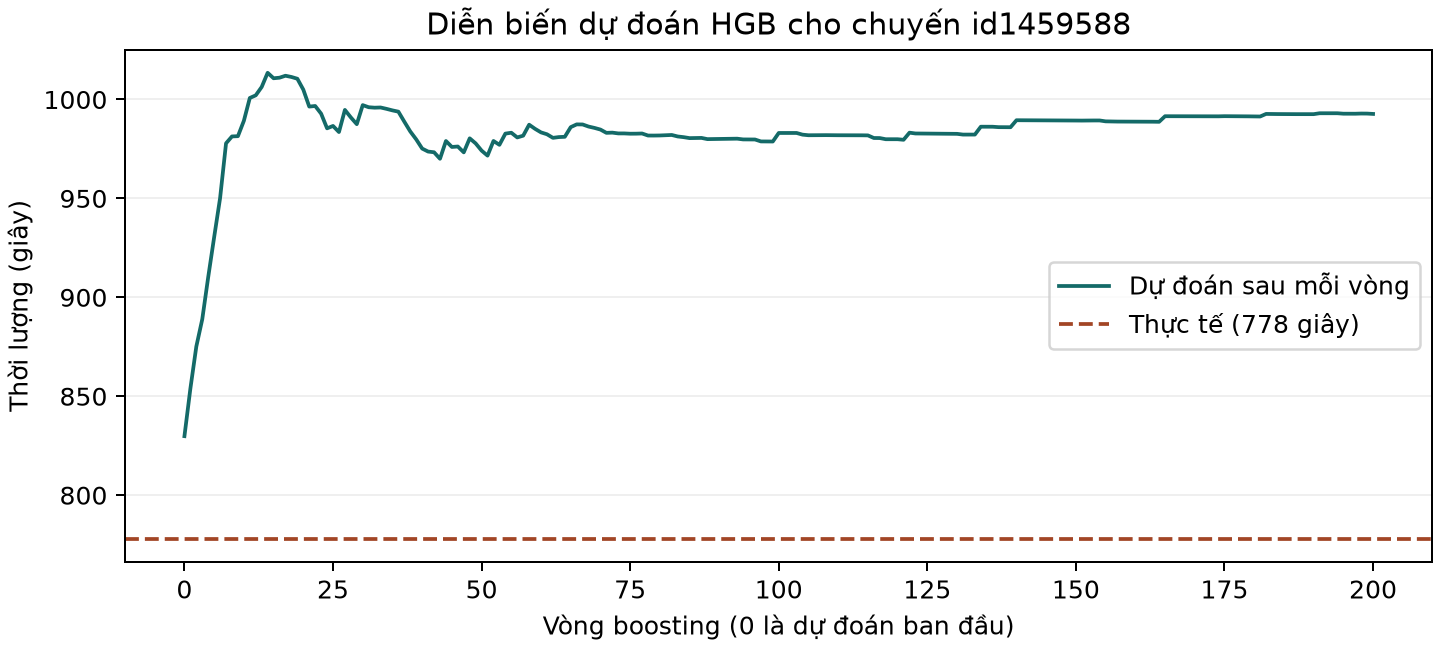

In [4]:
# 4. Đọc một số mốc trong lịch sử dự đoán của cùng chuyến
rounds = sorted({0, 1, 2, 3, 50, 100, model.n_iter_} & set(history.index))
print("Mức điều chỉnh tại vòng m bằng dự đoán vòng m trừ dự đoán vòng m−1.")
display(history.loc[rounds, ["điều chỉnh (s)", "dự đoán (s)"]].style.format(precision=3, na_rep="—"))
observed = trip["trip_duration"].item()
figure = plot_history(history, observed, trip_id)
figure_path = root / "reports/figures/hinh_hgb_200_vong.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=180)
plt.close(figure)
display(Image(filename=str(figure_path), width=760))

In [5]:
# 5. Đối chiếu vòng cuối với model.predict() và kết quả đã lưu khi đánh giá
saved = find_trip(root / "reports/predictions.csv", trip_id).iloc[0]
prediction = model.predict(X).item()
np.testing.assert_allclose([history.iloc[-1]["dự đoán (s)"], saved["hgb"]], prediction, rtol=0, atol=1e-8)
assert observed == saved["trip_duration"]
start = pd.Timestamp(saved["pickup_datetime"])
seconds = round(max(0, prediction))
eta = start + pd.Timedelta(seconds=seconds)
actual_arrival = start + pd.Timedelta(seconds=observed)
print(f"Vòng cuối = model.predict() = kết quả CSV: {prediction:.9f} giây")
print(f"Xuất phát {start:%H:%M:%S} | Dự đoán {seconds} giây | ETA {eta:%H:%M:%S}")
print(f"Thực tế {observed} giây | Đến lúc {actual_arrival:%H:%M:%S}")
print(f"Sai số tuyệt đối của riêng chuyến này: {abs(prediction - observed):.3f} giây")

Vòng cuối = model.predict() = kết quả CSV: 992.697802470 giây
Xuất phát 01:07:16 | Dự đoán 993 giây | ETA 01:23:49
Thực tế 778 giây | Đến lúc 01:20:14
Sai số tuyệt đối của riêng chuyến này: 214.698 giây
